In [1]:
%pip install "torch<2.15" --index-url https://download.pytorch.org/whl/cu126


Looking in indexes: https://download.pytorch.org/whl/cu126
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB 18.2 MB/s eta 0:02:23
   ---------------------------------------- 0.0/2.6 GB 18.1 MB/s eta 0:02:24
   ---------------------------------------- 0.0/2.6 GB 18.0 MB/s eta 0:02:24
   ---------------------------------------- 0.0/2.6 GB 17.7 MB/s eta 0:02:26
   ---------------------------------------- 0.0/2.6 GB 18.0 MB/s eta 0:02:24
   ---------------------------------------- 0.0/2.6 GB 18.5 MB/s eta 0:02:20
   ---------------------------------------- 0.0/2.6 GB 18.4 MB/s eta 0:02:21
   ---------------------------------------- 0.0/2.6 GB 18.7 MB/s eta 0:02:18
    --------------------------------------- 0.0/2.6 GB 18.8 MB/s eta 0:02:17
    --------------------------------------- 0.0/2.6 GB 18.7 MB/s eta 0:02:18
    --------------------------------------- 0.0/2.6 GB 18.7 MB/s eta 0:02:17
    ---------------------

In [1]:
import torch
print(torch.__version__, torch.version.cuda)
print(torch.cuda.is_available(), torch.cuda.get_arch_list())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

2.14.1+cu126 12.6
True ['sm_50', 'sm_60', 'sm_61', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']
NVIDIA GeForce 940MX


In [2]:
import time, torch.nn as nn

def bench(device, n=20):
    net = nn.Sequential(nn.Conv2d(13, 16, 3, padding=1), nn.ReLU(),
                        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                        nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
                        nn.Conv2d(32, 1, 1)).to(device)
    opt = torch.optim.Adam(net.parameters())
    x = torch.randn(8, 13, 128, 128, device=device)
    y = (torch.rand(8, 1, 128, 128, device=device) > 0.9).float()
    for i in range(n + 3):
        if i == 3:
            if device == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter()
        loss = nn.functional.binary_cross_entropy_with_logits(net(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n

print("cpu seconds per step :", round(bench("cpu"), 4))
print("cuda seconds per step:", round(bench("cuda"), 4))
print("peak GPU memory (MB):", round(torch.cuda.max_memory_allocated() / 1e6))

cpu seconds per step : 0.1661
cuda seconds per step: 0.1282
peak GPU memory (MB): 83


In [4]:
from pathlib import Path
import zipfile, time
import numpy as np
import torch

PROJECT_DIR = Path(r"G:\sen2fire-thesis")
REF_ZIP = PROJECT_DIR / "data" / "reference" / "Baseline_code.zip"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("torch", torch.__version__, "| device:", DEVICE)
print("Zip present:", REF_ZIP.exists())

torch 2.14.1+cu126 | device: cuda
Zip present: True


In [5]:
with zipfile.ZipFile(REF_ZIP) as zf:
    for n in zf.namelist():
        if n.endswith("Networks.py"):
            print(n)
            print(zf.read(n).decode("utf-8", errors="replace"))

model/Networks.py
import torch
from torch import nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.maxpool_conv(x)

cl

In [6]:
%%writefile unet_slim.py
import torch
from torch import nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, mid_channels=None):
        super().__init__()
        if not mid_channels:
            mid_channels = out_channels
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.double_conv(x)

class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.maxpool_conv = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_channels, out_channels))
    def forward(self, x):
        return self.maxpool_conv(x)

class Up(nn.Module):
    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()
        if bilinear:
            self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels, in_channels // 2)
        else:
            self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)
    def forward(self, x1, x2):
        x1 = self.up(x1)
        diffY = x2.size()[2] - x1.size()[2]
        diffX = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diffX // 2, diffX - diffX // 2, diffY // 2, diffY - diffY // 2])
        return self.conv(torch.cat([x2, x1], dim=1))

class OutConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)
    def forward(self, x):
        return self.conv(x)

class UNetSlim(nn.Module):
    """Authors' U-Net with a width setting. base=64 reproduces the original."""
    def __init__(self, n_classes=2, n_channels=13, base=16, bilinear=True):
        super().__init__()
        b, f = base, (2 if bilinear else 1)
        self.inc = DoubleConv(n_channels, b)
        self.down1 = Down(b, 2 * b)
        self.down2 = Down(2 * b, 4 * b)
        self.down3 = Down(4 * b, 8 * b)
        self.down4 = Down(8 * b, 16 * b // f)
        self.up1 = Up(16 * b, 8 * b // f, bilinear)
        self.up2 = Up(8 * b, 4 * b // f, bilinear)
        self.up3 = Up(4 * b, 2 * b // f, bilinear)
        self.up4 = Up(2 * b, b, bilinear)
        self.outc = OutConv(b, n_classes)
    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)

Writing unet_slim.py


In [7]:
import time, importlib
import torch.nn.functional as F
import unet_slim; importlib.reload(unet_slim)
from unet_slim import UNetSlim

def check(base, bs=8, size=128, n=8, device=DEVICE):
    model = UNetSlim(base=base).to(device)
    params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters())
    x = torch.randn(bs, 13, size, size, device=device)
    y = torch.randint(0, 2, (bs, size, size), device=device)
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for i in range(n + 2):
        if i == 2:
            if device == "cuda": torch.cuda.synchronize()
            t0 = time.perf_counter()
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    if device == "cuda": torch.cuda.synchronize()
    dt = (time.perf_counter() - t0) / n
    mem = torch.cuda.max_memory_allocated() / 1e6 if device == "cuda" else float("nan")
    return params, dt, mem

for base in (16, 32, 64):
    try:
        p, dt, mem = check(base)
        print(f"base={base:>2}  params={p/1e6:5.2f}M  {dt:.3f} s/step  peak GPU {mem:.0f} MB")
    except torch.cuda.OutOfMemoryError:
        print(f"base={base:>2}  out of GPU memory")
    torch.cuda.empty_cache()

base=16  params= 1.08M  0.421 s/step  peak GPU 428 MB
base=32  params= 4.32M  0.784 s/step  peak GPU 603 MB
base=64  params=17.27M  2.011 s/step  peak GPU 1069 MB


In [8]:
import pandas as pd

EXTRACT_DIR = PROJECT_DIR / "data" / "sen2fire"

def read_split(name):
    with zipfile.ZipFile(REF_ZIP) as zf:
        raw = zf.read(f"dataset/{name}.txt").decode("utf-8")
    return [l.strip() for l in raw.splitlines() if l.strip()]

splits = {s: read_split(s) for s in ("train", "val")}

t0 = time.perf_counter()
rows = []
for split, items in splits.items():
    for rel in items:
        with np.load(EXTRACT_DIR / rel) as d:
            rows.append((split, rel, int((d["label"] > 0).sum())))

idx = pd.DataFrame(rows, columns=["split", "rel", "fire_px"])
idx.to_csv(PROJECT_DIR / "data" / "unet_index.csv", index=False)
print(f"took {time.perf_counter() - t0:.0f} s")
print(idx.groupby("split").agg(
    patches=("rel", "size"),
    with_fire=("fire_px", lambda s: int((s > 0).sum())),
    fire_px=("fire_px", "sum"),
))

took 6 s
       patches  with_fire  fire_px
split                             
train     1458        153  9563997
val        504         94  4694012


In [9]:
CROP, N_FIRE = 128, 1500
rng = np.random.default_rng(0)

tr = idx[idx.split == "train"].reset_index(drop=True)
fire_p = tr[tr.fire_px > 0].reset_index(drop=True)
bg_p = tr[tr.fire_px == 0].reset_index(drop=True)
N = N_FIRE + len(bg_p)

X = np.empty((N, 12, CROP, CROP), dtype=np.int16)
A = np.empty((N, CROP, CROP), dtype=np.float16)
Y = np.empty((N, CROP, CROP), dtype=np.uint8)
src = []

def load(rel):
    with np.load(EXTRACT_DIR / rel) as d:
        return d["image"], d["aerosol"], d["label"]

def put(k, rel, img, aer, lab, r, c):
    X[k] = img[:, r:r + CROP, c:c + CROP]
    A[k] = aer[r:r + CROP, c:c + CROP]
    Y[k] = lab[r:r + CROP, c:c + CROP]
    src.append(rel)

t0, k = time.perf_counter(), 0
per = [N_FIRE // len(fire_p) + (1 if i < N_FIRE % len(fire_p) else 0) for i in range(len(fire_p))]
for rel, n in zip(fire_p.rel, per):
    img, aer, lab = load(rel)
    fr, fc = np.nonzero(lab)
    for _ in range(n):
        j = rng.integers(len(fr))
        r = int(np.clip(fr[j] - rng.integers(16, CROP - 16), 0, 512 - CROP))
        c = int(np.clip(fc[j] - rng.integers(16, CROP - 16), 0, 512 - CROP))
        put(k, rel, img, aer, lab, r, c); k += 1

for rel in bg_p.rel:
    img, aer, lab = load(rel)
    r, c = (int(v) for v in rng.integers(0, 512 - CROP + 1, size=2))
    put(k, rel, img, aer, lab, r, c); k += 1

assert k == N
np.savez(PROJECT_DIR / "data" / "crop_bank_train.npz", X=X, A=A, Y=Y, src=np.array(src))
print(f"{N} crops in {time.perf_counter() - t0:.0f} s | {(X.nbytes + A.nbytes + Y.nbytes) / 1e9:.2f} GB")
print("crops with fire:", int((Y.reshape(N, -1).max(1) > 0).sum()), "| fire share of pixels:", round(float(Y.mean()), 4))

2805 crops in 109 s | 1.24 GB
crops with fire: 1500 | fire share of pixels: 0.3126


x (8, 13, 128, 128) torch.float32 | y (8, 128, 128) torch.int64
per-channel mean of batch: [-0.08 -0.05 -0.02  0.03  0.04  0.03  0.03  0.05  0.05  0.08  0.17  0.16
 -0.06]
fire share in batch: 0.256


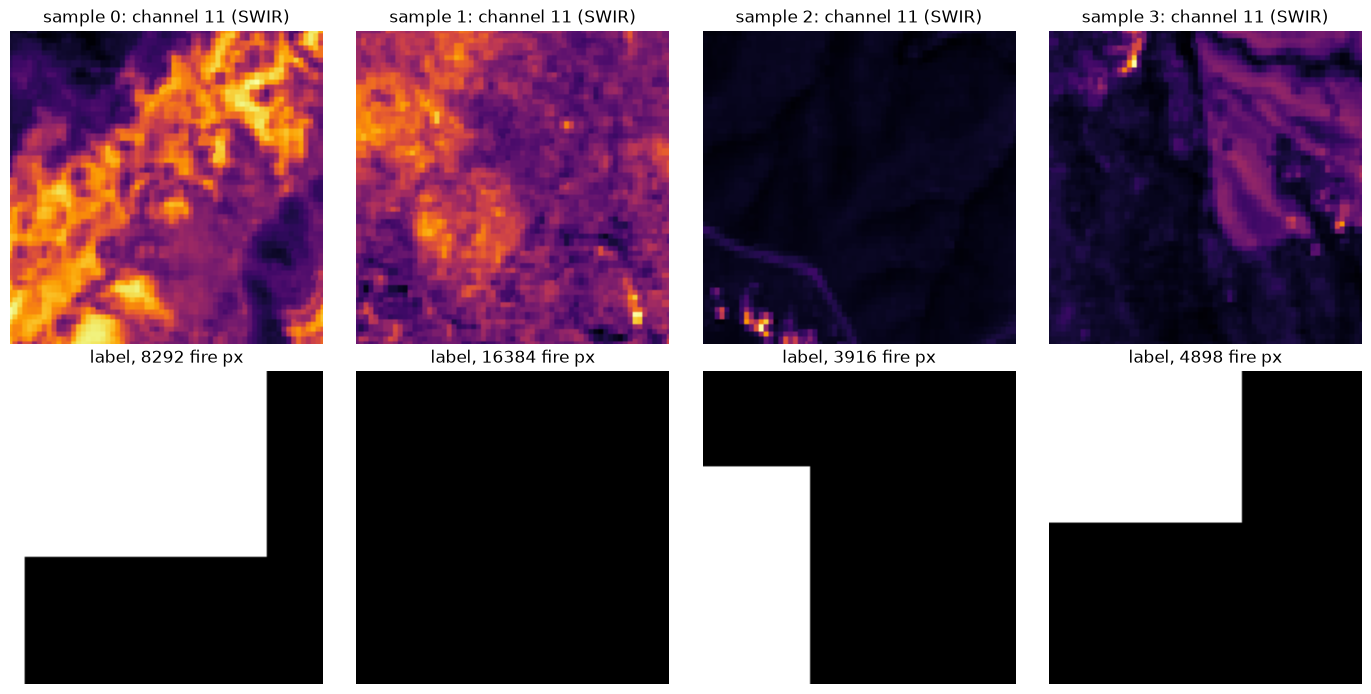

In [10]:
import matplotlib.pyplot as plt

fire_idx = np.arange(0, N_FIRE)
bg_idx = np.arange(N_FIRE, N)

sub = X[::6].astype(np.float32) / 10000.0
MEAN, STD = sub.mean(axis=(0, 2, 3)), sub.std(axis=(0, 2, 3)) + 1e-6
a = A[::6].astype(np.float32)
A_MEAN, A_STD = float(a.mean()), float(a.std()) + 1e-6
del sub, a

MEAN13 = np.concatenate([MEAN, [A_MEAN]]).astype(np.float32).reshape(1, 13, 1, 1)
STD13 = np.concatenate([STD, [A_STD]]).astype(np.float32).reshape(1, 13, 1, 1)
np.savez(PROJECT_DIR / "results" / "unet_norm_stats.npz", mean=MEAN13, std=STD13)

def make_batch(rng, bs=8, augment=True):
    ids = np.concatenate([rng.choice(fire_idx, bs // 2, replace=False),
                          rng.choice(bg_idx, bs - bs // 2, replace=False)])
    x = np.concatenate([X[ids].astype(np.float32) / 10000.0,
                        A[ids].astype(np.float32)[:, None]], axis=1)
    x = (x - MEAN13) / STD13
    y = Y[ids].astype(np.int64)
    if augment:
        xs, ys = [], []
        for i in range(len(ids)):
            k = int(rng.integers(4))
            xi, yi = np.rot90(x[i], k, axes=(1, 2)), np.rot90(y[i], k)
            if rng.random() < 0.5:
                xi, yi = xi[:, :, ::-1], yi[:, ::-1]
            xs.append(np.ascontiguousarray(xi)); ys.append(np.ascontiguousarray(yi))
        x, y = np.stack(xs), np.stack(ys)
    return torch.from_numpy(x), torch.from_numpy(y)

rng = np.random.default_rng(1)
xb, yb = make_batch(rng)
print("x", tuple(xb.shape), xb.dtype, "| y", tuple(yb.shape), yb.dtype)
print("per-channel mean of batch:", np.round(xb.mean(dim=(0, 2, 3)).numpy(), 2))
print("fire share in batch:", round(float(yb.float().mean()), 3))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    axes[0, i].imshow(xb[i, 11].numpy(), cmap="inferno")
    axes[0, i].set_title(f"sample {i}: channel 11 (SWIR)")
    axes[1, i].imshow(yb[i].numpy(), cmap="gray")
    axes[1, i].set_title(f"label, {int(yb[i].sum())} fire px")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

In [11]:
import torch.nn.functional as F
import importlib, unet_slim
importlib.reload(unet_slim)
from unet_slim import UNetSlim

torch.manual_seed(0)
rng = np.random.default_rng(2)
model = UNetSlim(n_classes=2, n_channels=13, base=16).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

xb, yb = make_batch(rng, bs=8, augment=False)
xb, yb = xb.to(DEVICE), yb.to(DEVICE)

t0 = time.perf_counter()
model.train()
for step in range(1, 151):
    loss = F.cross_entropy(model(xb), yb)
    opt.zero_grad(); loss.backward(); opt.step()
    if step == 1 or step % 25 == 0:
        print(f"step {step:>3}  loss {loss.item():.4f}")
print(f"{time.perf_counter() - t0:.0f} s")

model.eval()
with torch.no_grad():
    pred = model(xb).argmax(1)
tp = int(((pred == 1) & (yb == 1)).sum())
fp = int(((pred == 1) & (yb == 0)).sum())
fn = int(((pred == 0) & (yb == 1)).sum())
print(f"memorised batch: precision {tp / max(tp + fp, 1):.3f}  recall {tp / max(tp + fn, 1):.3f}")

step   1  loss 0.6985
step  25  loss 0.2017
step  50  loss 0.1341
step  75  loss 0.0941
step 100  loss 0.0686
step 125  loss 0.0518
step 150  loss 0.0541
60 s
memorised batch: precision 0.571  recall 0.986


In [12]:
def prec_rec(pred, y):
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    return round(tp / max(tp + fp, 1), 3), round(tp / max(tp + fn, 1), 3)

with torch.no_grad():
    model.train()
    p_train = model(xb).argmax(1)
    for _ in range(30):
        model(xb)
    model.eval()
    p_eval = model(xb).argmax(1)

print("train-mode (precision, recall):", prec_rec(p_train, yb))
print("eval after refresh            :", prec_rec(p_eval, yb))

train-mode (precision, recall): (0.987, 0.99)
eval after refresh            : (0.987, 0.99)


In [13]:
STEPS, BS, LR = 3000, 8, 1e-3
torch.manual_seed(0)
rng = np.random.default_rng(0)

model = UNetSlim(n_classes=2, n_channels=13, base=16).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=STEPS, eta_min=1e-5)
CKPT = PROJECT_DIR / "results" / "unet_b16_s3000.pt"

model.train()
run, t0 = 0.0, time.perf_counter()
for step in range(1, STEPS + 1):
    xb, yb = make_batch(rng, bs=BS, augment=True)
    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
    loss = F.cross_entropy(model(xb), yb)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    run += loss.item()
    if step % 100 == 0:
        print(f"step {step:>4}  loss {run / 100:.4f}  lr {sched.get_last_lr()[0]:.1e}  {time.perf_counter() - t0:.0f} s")
        run = 0.0
    if step % 500 == 0:
        torch.save(model.state_dict(), CKPT)
torch.save(model.state_dict(), CKPT)
print("saved", CKPT)

step  100  loss 0.5883  lr 1.0e-03  43 s
step  200  loss 0.5436  lr 9.9e-04  87 s
step  300  loss 0.5293  lr 9.8e-04  131 s
step  400  loss 0.5149  lr 9.6e-04  177 s
step  500  loss 0.4916  lr 9.3e-04  222 s
step  600  loss 0.5012  lr 9.1e-04  269 s
step  700  loss 0.4902  lr 8.7e-04  315 s
step  800  loss 0.4880  lr 8.4e-04  361 s
step  900  loss 0.4797  lr 8.0e-04  406 s
step 1000  loss 0.4749  lr 7.5e-04  451 s
step 1100  loss 0.4768  lr 7.1e-04  496 s
step 1200  loss 0.4679  lr 6.6e-04  541 s
step 1300  loss 0.4571  lr 6.1e-04  588 s
step 1400  loss 0.4848  lr 5.6e-04  633 s
step 1500  loss 0.4702  lr 5.0e-04  678 s
step 1600  loss 0.4388  lr 4.5e-04  723 s
step 1700  loss 0.4696  lr 4.0e-04  769 s
step 1800  loss 0.4665  lr 3.5e-04  814 s
step 1900  loss 0.4817  lr 3.0e-04  859 s
step 2000  loss 0.4368  lr 2.6e-04  904 s
step 2100  loss 0.4478  lr 2.1e-04  949 s
step 2200  loss 0.4476  lr 1.7e-04  995 s
step 2300  loss 0.4528  lr 1.4e-04  1040 s
step 2400  loss 0.4251  lr 1.0e-04 

In [14]:
from sklearn.metrics import average_precision_score

val = idx[idx.split == "val"].reset_index(drop=True)
model = UNetSlim(n_classes=2, n_channels=13, base=16).to(DEVICE)
model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
model.eval()

S = np.empty((len(val), 512, 512), dtype=np.float16)
YV = np.empty((len(val), 512, 512), dtype=np.uint8)

def prep(rel):
    with np.load(EXTRACT_DIR / rel) as d:
        img, aer, lab = d["image"], d["aerosol"], d["label"]
    x = np.concatenate([img.astype(np.float32) / 10000.0, aer.astype(np.float32)[None]], axis=0)
    return (x - MEAN13[0]) / STD13[0], lab

t0, BSZ = time.perf_counter(), 4
with torch.no_grad():
    for s in range(0, len(val), BSZ):
        items = [prep(r) for r in val.rel[s:s + BSZ]]
        xb = torch.from_numpy(np.stack([i[0] for i in items])).to(DEVICE)
        z = model(xb)
        S[s:s + len(items)] = (z[:, 1] - z[:, 0]).cpu().numpy().astype(np.float16)
        YV[s:s + len(items)] = np.stack([i[1] for i in items])
        if (s // BSZ) % 25 == 0:
            print(s, f"{time.perf_counter() - t0:.0f} s")

np.savez(PROJECT_DIR / "data" / "unet_b16_s3000_val_scores.npz", S=S, YV=YV, rel=val.rel.values)

rng = np.random.default_rng(0)
pick = rng.choice(S.size, 5_000_000, replace=False)
y_s, s_s = YV.ravel()[pick], S.ravel()[pick].astype(np.float32)
print(f"quick look: AP {average_precision_score(y_s, s_s):.3f} | no-skill AP {y_s.mean():.3f}")

0 1 s
100 44 s
200 83 s
300 123 s
400 163 s
500 203 s
quick look: AP 0.311 | no-skill AP 0.035


In [15]:
import inspect, importlib, evalkit
importlib.reload(evalkit)
for n in dir(evalkit):
    f = getattr(evalkit, n)
    if callable(f) and not n.startswith("_") and getattr(f, "__module__", None) == "evalkit":
        print(n, inspect.signature(f))
        print("    ", (inspect.getdoc(f) or "").split("\n")[0])

average_precision (y_true, score, weight=None)
     
best_f1_threshold (y_true, score, weight=None)
     
confusion (y_true, y_pred, weight=None)
     
plot_confusion (cm, title, ax)
     
recall_at_fpr (y_true, score, fpr_max, weight=None)
     
scores (cm)
     


In [16]:
import evalkit

NB = 4000
lo, hi = float(S.min()), float(S.max())
edges = np.linspace(lo, hi, NB + 1)
hp = np.zeros(NB, np.int64)
hn = np.zeros(NB, np.int64)
for i in range(len(S)):
    s = S[i].astype(np.float32)
    y = YV[i] > 0
    hp += np.histogram(s[y], bins=edges)[0]
    hn += np.histogram(s[~y], bins=edges)[0]

centres = 0.5 * (edges[:-1] + edges[1:])
y_h = np.r_[np.ones(NB), np.zeros(NB)]
s_h = np.r_[centres, centres]
w_h = np.r_[hp, hn].astype(np.float64)
print("pixels:", int(w_h.sum()), "| fire:", int(hp.sum()), "| fire share:", round(float(hp.sum() / w_h.sum()), 4))

ap_hist = evalkit.average_precision(y_h, s_h, weight=w_h)
ap_sub = evalkit.average_precision(y_s, s_s)
print("AP weighted bins:", ap_hist, "| AP 5M sample:", ap_sub)

for fpr in (0.001, 0.01, 0.05):
    print("recall at FPR", fpr, "->", repr(evalkit.recall_at_fpr(y_h, s_h, fpr, weight=w_h)))

print("best F1 threshold ->", repr(evalkit.best_f1_threshold(y_h, s_h, weight=w_h)))

pixels: 132120576 | fire: 4694012 | fire share: 0.0355
AP weighted bins: 0.3113670646783339 | AP 5M sample: 0.3111423446469736
recall at FPR 0.001 -> 0.05623739351326754
recall at FPR 0.01 -> 0.2729349648019647
recall at FPR 0.05 -> 0.479252289938756
best F1 threshold -> 1.0370356445312505


In [17]:
thr = evalkit.best_f1_threshold(y_h, s_h, weight=w_h)
cm = evalkit.confusion(y_h, (s_h >= thr).astype(int), weight=w_h)
print("threshold:", thr)
print("confusion:", repr(cm))
print("scores   :", repr(evalkit.scores(cm)))

rows = [("unet_b16_s3000", "val_pixel", "AP", ap_hist)]
for fpr in (0.001, 0.01, 0.05):
    rows.append(("unet_b16_s3000", "val_pixel", f"recall_at_fpr_{fpr}",
                 evalkit.recall_at_fpr(y_h, s_h, fpr, weight=w_h)))
res = pd.DataFrame(rows, columns=["model", "split", "metric", "value"])
res.to_csv(PROJECT_DIR / "results" / "unet_b16_s3000_results.csv", index=False)
print(res.to_string(index=False))

for p in sorted((PROJECT_DIR / "results").glob("*.csv")):
    print("\n", p.name)
    print(pd.read_csv(p).head(8).to_string())

threshold: 1.0370356445312505
confusion: {'TP': 1789225.0, 'FP': 2395384.0, 'FN': 2904787.0, 'TN': 125031180.0}
scores   : {'precision': 0.4275728030982106, 'recall': 0.3811717993051573, 'f1': 0.4030411929960745, 'iou': 0.25238045667077985, 'fpr': 0.01879815263636866, 'prevalence': 0.035528243534148685, 'flag_all_f1': 0.06861858912296692}
         model     split              metric    value
unet_b16_s3000 val_pixel                  AP 0.311367
unet_b16_s3000 val_pixel recall_at_fpr_0.001 0.056237
unet_b16_s3000 val_pixel  recall_at_fpr_0.01 0.272935
unet_b16_s3000 val_pixel  recall_at_fpr_0.05 0.479252

 baseline_threshold_results.csv
   split  level  precision  recall     f1
0  train  patch      0.886   0.458  0.603
1    val  patch      0.757   0.596  0.667
2    val  pixel      0.508   0.035  0.066

 loso_scenes123_tabular.csv
   held_out                model        ap      lift  r_fpr_0125   r_fpr_1  precision    recall        f1
0         1  Logistic regression  0.179402  5.222877 

In [18]:
r0125 = evalkit.recall_at_fpr(y_h, s_h, 0.00125, weight=w_h)
r1 = evalkit.recall_at_fpr(y_h, s_h, 0.01, weight=w_h)
sc = evalkit.scores(cm)

row = {"model": "U-Net (base 16, 3000 steps)",
       "thr": round(float(1 / (1 + np.exp(-thr))), 3),
       "ap": round(ap_hist, 3),
       "recall@fpr0.125%": round(r0125, 3), "recall@fpr1%": round(r1, 3),
       "precision": round(sc["precision"], 3), "recall": round(sc["recall"], 3),
       "f1": round(sc["f1"], 3), "iou": round(sc["iou"], 3), "fpr": round(sc["fpr"], 3)}

tab = pd.read_csv(PROJECT_DIR / "results" / "tabular_models_val.csv")
tab = pd.concat([tab, pd.DataFrame([row])], ignore_index=True)
tab["lift"] = (tab["ap"] / sc["prevalence"]).round(2)
tab.to_csv(PROJECT_DIR / "results" / "tabular_models_val_with_unet.csv", index=False)
print(tab.to_string(index=False))

                      model   thr    ap  recall@fpr0.125%  recall@fpr1%  precision  recall    f1   iou   fpr  lift
              Random Forest 0.366 0.092             0.018         0.053      0.085   0.427 0.142 0.076 0.170  2.59
        Logistic regression 0.292 0.125             0.040         0.093      0.096   0.374 0.153 0.083 0.129  3.52
                   CatBoost 0.360 0.103             0.018         0.072      0.092   0.439 0.151 0.082 0.160  2.90
U-Net (base 16, 3000 steps) 0.738 0.311             0.065         0.273      0.428   0.381 0.403 0.252 0.019  8.75


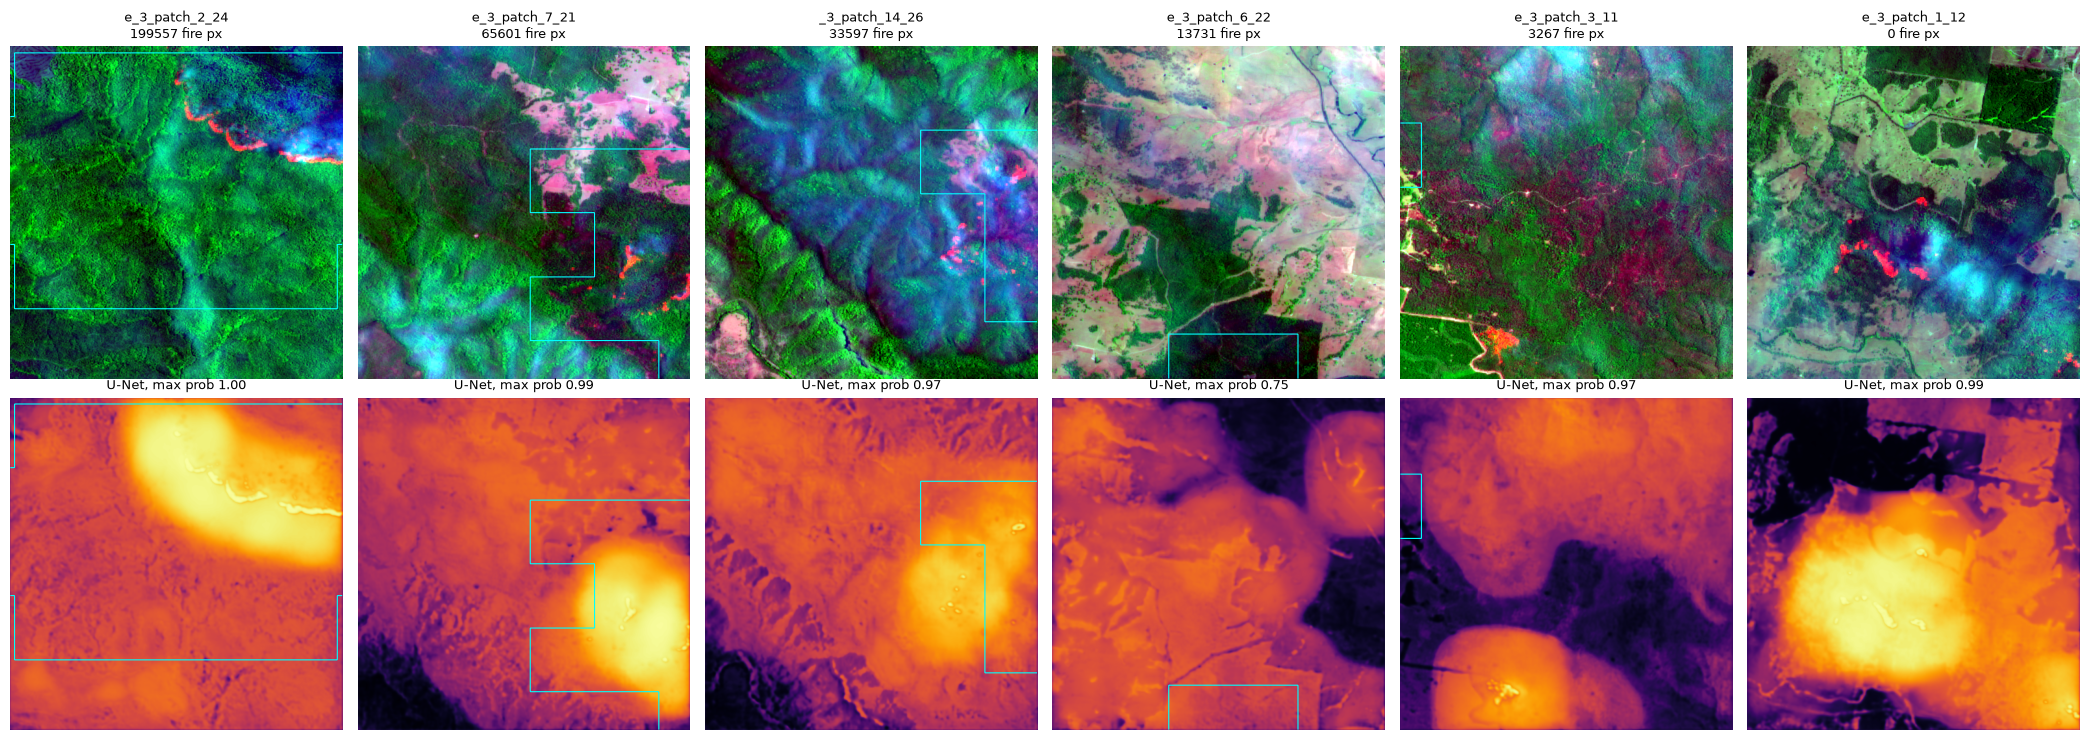

In [19]:
import matplotlib.pyplot as plt

PATCHES = None

if PATCHES is None:
    fire_rows = val.index[val.fire_px > 0].to_numpy()
    order = fire_rows[np.argsort(val.fire_px.values[fire_rows])]
    pick = [int(order[int(q * (len(order) - 1))]) for q in (1.0, 0.75, 0.5, 0.25, 0.1)]
    nonfire = val.index[val.fire_px == 0].to_numpy()
    pick.append(int(nonfire[np.argmax([np.percentile(S[i].astype(np.float32), 99.9) for i in nonfire])]))
else:
    pick = [int(val.index[val.rel == p][0]) for p in PATCHES]

def stretch(b, lo=2, hi=99.5):
    a, c = np.percentile(b, [lo, hi])
    return np.clip((b - a) / (c - a + 1e-6), 0, 1)

fig, axes = plt.subplots(2, len(pick), figsize=(3.5 * len(pick), 7.5))
for k, i in enumerate(pick):
    with np.load(EXTRACT_DIR / val.rel[i]) as d:
        im = d["image"].astype(np.float32)
    comp = np.stack([stretch(im[11]), stretch(im[7]), stretch(im[3])], axis=-1)
    lab = YV[i]
    prob = 1 / (1 + np.exp(-S[i].astype(np.float32)))
    axes[0, k].imshow(comp)
    axes[1, k].imshow(prob, cmap="inferno", vmin=0, vmax=1)
    for r in (0, 1):
        if lab.any():
            axes[r, k].contour(lab, levels=[0.5], colors="cyan", linewidths=0.8)
        axes[r, k].axis("off")
    axes[0, k].set_title(f"{Path(val.rel[i]).stem[-14:]}\n{int(lab.sum())} fire px", fontsize=9)
    axes[1, k].set_title(f"U-Net, max prob {prob.max():.2f}", fontsize=9)
plt.tight_layout()
plt.savefig(PROJECT_DIR / "results" / "unet_examples_val.png", dpi=110)
plt.show()